In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [2]:
import pandas as pd
import numpy as np
train = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')
test = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')
print("Train shape :" ,train.shape)
print("Test shape : ",test.shape)

Train shape : (1460, 81)
Test shape :  (1459, 80)


In [3]:
pd.set_option('display.max_columns',None)
display(train.head())
print(train.dtypes.value_counts())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


object     43
int64      35
float64     3
Name: count, dtype: int64


In [4]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending = False)
missing_pct = (missing / len(train)*100).round(1)
display(pd.DataFrame({'Missing Count' : missing, 'Missing %' : missing_pct}))
print("Columns with missing Values :",len(missing))


,Missing Count,Missing %
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


Columns with missing Values : 19


In [5]:
# Check: NaN ki ginti = "cheez nahi hai" wali ginti?
print("PoolQC NaN         :", train['PoolQC'].isnull().sum(),      "| PoolArea == 0     :", (train['PoolArea'] == 0).sum())
print("FireplaceQu NaN    :", train['FireplaceQu'].isnull().sum(), "| Fireplaces == 0   :", (train['Fireplaces'] == 0).sum())
print("GarageType NaN     :", train['GarageType'].isnull().sum(),  "| GarageArea == 0    :", (train['GarageArea'] == 0).sum())
print("BsmtQual NaN       :", train['BsmtQual'].isnull().sum(),    "| TotalBsmtSF == 0   :", (train['TotalBsmtSF'] == 0).sum())

# MasVnrType ka case
print("\nMasVnrType NaN, MasVnrArea maloom :", (train['MasVnrType'].isnull() & train['MasVnrArea'].notnull()).sum())
print("MasVnrType aur MasVnrArea dono NaN:", (train['MasVnrType'].isnull() & train['MasVnrArea'].isnull()).sum())

# Duplicates
print("\nDuplicate rows:", train.duplicated().sum())
print("Duplicate Id  :", train['Id'].duplicated().sum())

PoolQC NaN         : 1453 | PoolArea == 0     : 1453
FireplaceQu NaN    : 690 | Fireplaces == 0   : 690
GarageType NaN     : 81 | GarageArea == 0    : 81
BsmtQual NaN       : 37 | TotalBsmtSF == 0   : 37

MasVnrType NaN, MasVnrArea maloom : 864
MasVnrType aur MasVnrArea dono NaN: 8

Duplicate rows: 0
Duplicate Id  : 0


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness(original) : 1.88
Skewness (Log1p)  : 0.12


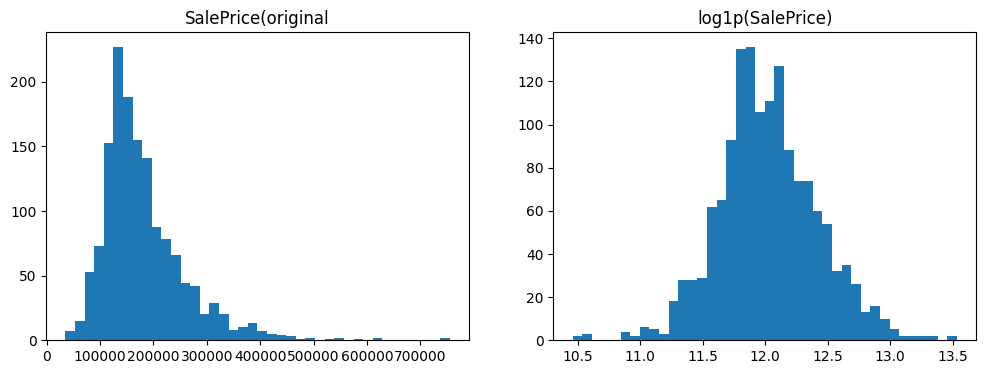

In [6]:
import matplotlib.pyplot as plt
display(train['SalePrice'].describe())
print("Skewness(original) :",round(train['SalePrice'].skew(),2))
print("Skewness (Log1p)  :",round(np.log1p(train['SalePrice']).skew(),2))

fig,axes = plt.subplots(1,2,figsize = (12,4))
axes[0].hist(train['SalePrice'],bins=40)
axes[0].set_title('SalePrice(original')
axes[1].hist(np.log1p(train['SalePrice']),bins = 40)
axes[1].set_title('log1p(SalePrice)')
plt.show()

In [7]:
numeric_cols = train.select_dtypes(include = np.number).columns.drop(['Id','SalePrice'])
log_price = np.log1p(train['SalePrice'])
corr = train[numeric_cols].corrwith(log_price).sort_values(ascending =False)
print("Top 10(positive) :")
display(corr.head(10).round(3))
print("Bottom 5 (negative) :")
display(corr.tail(5).round(3))

Top 10(positive) :


OverallQual     0.817
GrLivArea       0.701
GarageCars      0.681
GarageArea      0.651
TotalBsmtSF     0.612
1stFlrSF        0.597
FullBath        0.595
YearBuilt       0.587
YearRemodAdd    0.566
GarageYrBlt     0.541
dtype: float64

Bottom 5 (negative) :


YrSold          -0.037
LowQualFinSF    -0.038
MSSubClass      -0.074
KitchenAbvGr    -0.148
EnclosedPorch   -0.149
dtype: float64

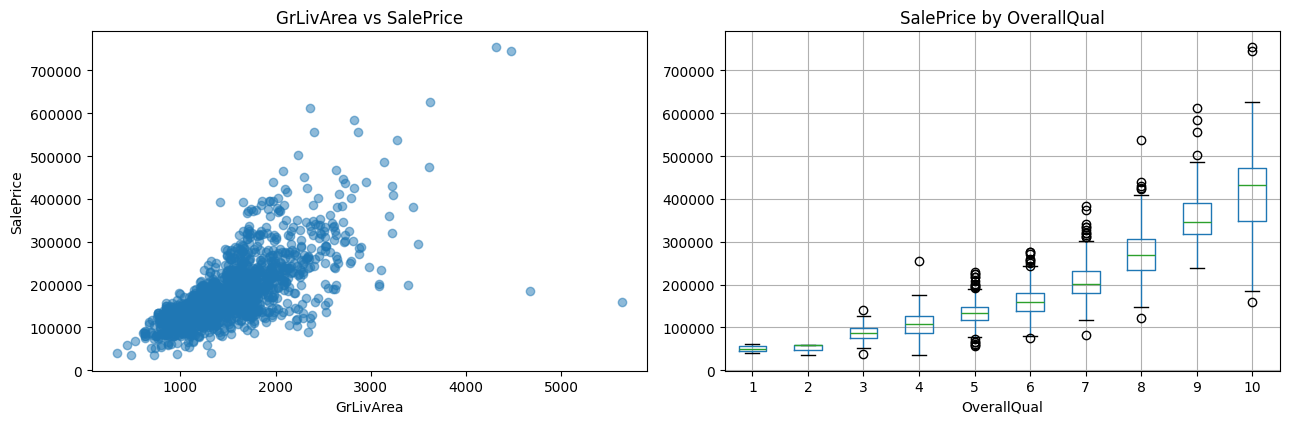

,Id,GrLivArea,OverallQual,SalePrice,SaleCondition
523,524,4676,10,184750,Partial
691,692,4316,10,755000,Normal
1182,1183,4476,10,745000,Abnorml
1298,1299,5642,10,160000,Partial


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(train['GrLivArea'], train['SalePrice'], alpha=0.5)
axes[0].set_xlabel('GrLivArea')
axes[0].set_ylabel('SalePrice')
axes[0].set_title('GrLivArea vs SalePrice')

train.boxplot(column='SalePrice', by='OverallQual', ax=axes[1])
axes[1].set_title('SalePrice by OverallQual')
axes[1].set_xlabel('OverallQual')

plt.suptitle('')
plt.tight_layout()
plt.show()

# Bahut bade area wale ghar ko alag se dekhte hain
display(train.loc[train['GrLivArea'] > 4000, ['Id', 'GrLivArea', 'OverallQual', 'SalePrice', 'SaleCondition']])

In [9]:
nb = (train.groupby('Neighborhood')['SalePrice'].agg(['count','median']).sort_values('median',ascending = False))
display(nb)
print("Neighborhoods:",len(nb))

,count,median
Neighborhood,,
NridgHt,77,315000.0
NoRidge,41,301500.0
StoneBr,25,278000.0
Timber,38,228475.0
Somerst,86,225500.0
Veenker,11,218000.0
Crawfor,51,200624.0
ClearCr,28,200250.0
CollgCr,150,197200.0


Neighborhoods: 25


In [10]:
skew= train[numeric_cols].skew().sort_values(ascending = False)
print("10 features of skew ")
display(skew.head(10).round(2))

# Do important features par log ka asar
for c in ['GrLivArea', 'LotArea']:
    print(f"{c}: {train[c].skew():.2f} -> log1p ke baad {np.log1p(train[c]).skew():.2f}")

# Sabse skewed 6 features mein kitne percent values zero hain
for c in skew.head(6).index:
    print(f"{c}: {(train[c] == 0).mean() * 100:.1f}% values zero hain")

10 features of skew 


MiscVal          24.48
PoolArea         14.83
LotArea          12.21
3SsnPorch        10.30
LowQualFinSF      9.01
KitchenAbvGr      4.49
BsmtFinSF2        4.26
ScreenPorch       4.12
BsmtHalfBath      4.10
EnclosedPorch     3.09
dtype: float64

GrLivArea: 1.37 -> log1p ke baad -0.01
LotArea: 12.21 -> log1p ke baad -0.14
MiscVal: 96.4% values zero hain
PoolArea: 99.5% values zero hain
LotArea: 0.0% values zero hain
3SsnPorch: 98.4% values zero hain
LowQualFinSF: 98.2% values zero hain
KitchenAbvGr: 0.1% values zero hain


In [11]:
for c in ['ExterQual','BsmtQual']:
    print(f"---{c}---")
    display(train.groupby(c,dropna =False)['SalePrice'].agg(['count','median']).sort_values('median',ascending = False))

---ExterQual---


,count,median
ExterQual,,
Ex,52,364606.5
Gd,488,220000.0
TA,906,139450.0
Fa,14,82250.0


---BsmtQual---


,count,median
BsmtQual,,
Ex,121,318000.0
Gd,618,192070.0
TA,649,135500.0
Fa,35,112000.0
NaN,37,101800.0


In [12]:
outlier_ids = [524,1299]
print("Train row before :" ,len(train))
train = train[~train['Id'].isin(outlier_ids)].reset_index(drop = True)
print("Train row after :", len(train))
y = np.log1p(train['SalePrice'])
train_features = train.drop(columns = ['SalePrice'])

print("Test Row :",len(test))
print("Y Shape :",y.shape,"| train Features Shape :", train_features.shape )
print(" y values : ", y.head(3).round(2).tolist())


Train row before : 1460
Train row after : 1458
Test Row : 1459
Y Shape : (1458,) | train Features Shape : (1458, 80)
 y values :  [12.25, 12.11, 12.32]


In [13]:
none_cols = ['Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'PoolQC', 'Fence', 'MiscFeature', 'MasVnrType']

zero_cols = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'GarageCars', 'GarageArea']

for df in [train_features,test]:
    for c in none_cols:
        df[c]= df[c].fillna('None')
    for c in zero_cols:
        df[c]=df[c].fillna(0)

def remaining_missing(df):
    m=df.isnull().sum()
    return m[m > 0].sort_values(ascending = False)
print("Train values Missing :")
display(remaining_missing(train_features))
print("Test Missing Values :")
display(remaining_missing(test))

Train values Missing :


LotFrontage    259
GarageYrBlt     81
Electrical       1
dtype: int64

Test Missing Values :


LotFrontage    227
GarageYrBlt     78
MSZoning         4
Functional       2
Utilities        2
Exterior2nd      1
Exterior1st      1
KitchenQual      1
SaleType         1
dtype: int64

In [14]:
# 1. GarageYrBlt: garage ka saal ghar ke saal se fill (fixed rule, koi statistic nahi)
for df in [train_features, test]:
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

# 2. LotFrontage: Neighborhood-wise median, TRAIN se seekho
lot_median_by_nb = train_features.groupby('Neighborhood')['LotFrontage'].median()
lot_median_overall = train_features['LotFrontage'].median()

for df in [train_features, test]:
    df['LotFrontage'] = df['LotFrontage'].fillna(df['Neighborhood'].map(lot_median_by_nb))
    df['LotFrontage'] = df['LotFrontage'].fillna(lot_median_overall)  # safety net

# 3. Baaki chhote categorical: train ka mode
mode_cols = ['Electrical', 'MSZoning', 'Functional', 'Utilities',
             'Exterior1st', 'Exterior2nd', 'KitchenQual', 'SaleType']
modes_used = {}
for c in mode_cols:
    modes_used[c] = train_features[c].mode()[0]
    for df in [train_features, test]:
        df[c] = df[c].fillna(modes_used[c])

print("Modes useage :", modes_used)
print("LotFrontage overall median:", lot_median_overall)
print("Neighborhood medians range:", lot_median_by_nb.min(), "se", lot_median_by_nb.max())
print("\nTotal train missing:", train_features.isnull().sum().sum())
print("Total test missing :", test.isnull().sum().sum())  

Modes useage : {'Electrical': 'SBrkr', 'MSZoning': 'RL', 'Functional': 'Typ', 'Utilities': 'AllPub', 'Exterior1st': 'VinylSd', 'Exterior2nd': 'VinylSd', 'KitchenQual': 'TA', 'SaleType': 'WD'}
LotFrontage overall median: 69.0
Neighborhood medians range: 21.0 se 91.0

Total train missing: 0
Total test missing : 0


In [15]:
quality_scale = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
quality_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']

fintype_scale = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
other_scales = {
    'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
    'BsmtFinType1': fintype_scale,
    'BsmtFinType2': fintype_scale,
    'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3},
}
ordinal_cols = quality_cols + list(other_scales)

for df in [train_features, test]:
    for c in quality_cols:
        df[c] = df[c].map(quality_scale)
    for c, scale in other_scales.items():
        df[c] = df[c].map(scale)
    df['MSSubClass'] = df['MSSubClass'].astype(str)

# Checks
print("New NaN (train, test):",
      train_features[ordinal_cols].isnull().sum().sum(), test[ordinal_cols].isnull().sum().sum())
print("Dtypes:", train_features[ordinal_cols].dtypes.value_counts().to_dict())
print("MSSubClass dtype:", train_features['MSSubClass'].dtype)
display(train_features[ordinal_cols].corrwith(y).sort_values(ascending=False).round(2))

New NaN (train, test): 0 0
Dtypes: {dtype('int64'): 14}
MSSubClass dtype: object


ExterQual       0.68
KitchenQual     0.67
BsmtQual        0.62
GarageFinish    0.61
FireplaceQu     0.55
HeatingQC       0.47
GarageQual      0.36
BsmtExposure    0.36
GarageCond      0.36
BsmtFinType1    0.33
BsmtCond        0.27
PoolQC          0.08
ExterCond       0.05
BsmtFinType2    0.01
dtype: float64

In [16]:
for df in [train_features, test]:
    df['TotalSF'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath'] = (df['FullBath'] + 0.5 * df['HalfBath']
                       + df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'])
    df['HouseAge'] = df['YrSold'] - df['YearBuilt']
    df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']
    df['HasPool'] = (df['PoolArea'] > 0).astype(int)

new_feats = ['TotalSF', 'TotalBath', 'HouseAge', 'RemodAge', 'HasPool']
display(train_features[new_feats].describe().round(1))
print(train_features[new_feats].corrwith(y).round(2))


print("\nHouseAge negative (train, test):", (train_features['HouseAge'] < 0).sum(), (test['HouseAge'] < 0).sum())
print("GarageYrBlt max (train, test):", train_features['GarageYrBlt'].max(), test['GarageYrBlt'].max())
print("Utilities:", train_features['Utilities'].value_counts().to_dict())

,TotalSF,TotalBath,HouseAge,RemodAge,HasPool
count,1458.0,1458.0,1458.0,1458.0,1458.0
mean,2557.2,2.2,36.6,23.0,0.0
std,774.1,0.8,30.2,20.6,0.1
min,334.0,1.0,0.0,0.0,0.0
25%,2008.5,2.0,8.0,4.0,0.0
50%,2473.0,2.0,35.0,14.0,0.0
75%,3002.2,2.5,54.0,41.0,0.0
max,6872.0,6.0,136.0,60.0,1.0


TotalSF      0.83
TotalBath    0.68
HouseAge    -0.59
RemodAge    -0.57
HasPool      0.08
dtype: float64

HouseAge negative (train, test): 0 1
GarageYrBlt max (train, test): 2010.0 2207.0
Utilities: {'AllPub': 1457, 'NoSeWa': 1}


In [17]:
print("--- Test: GarageYrBlt 2010 se bada ---")
display(test.loc[test['GarageYrBlt'] > 2010,
                 ['Id', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt', 'GarageType', 'YrSold']])

print("--- Test: HouseAge negative ---")
display(test.loc[test['HouseAge'] < 0,
                 ['Id', 'YearBuilt', 'YearRemodAdd', 'YrSold', 'SaleCondition', 'HouseAge', 'RemodAge']])

print("RemodAge negative (train, test):", (train_features['RemodAge'] < 0).sum(), (test['RemodAge'] < 0).sum())
print("Utilities (test):", test['Utilities'].value_counts().to_dict())

--- Test: GarageYrBlt 2010 se bada ---


,Id,YearBuilt,YearRemodAdd,GarageYrBlt,GarageType,YrSold
1132,2593,2006,2007,2207.0,Attchd,2007


--- Test: HouseAge negative ---


,Id,YearBuilt,YearRemodAdd,YrSold,SaleCondition,HouseAge,RemodAge
1089,2550,2008,2009,2007,Partial,-1,-2


RemodAge negative (train, test): 0 2
Utilities (test): {'AllPub': 1459}


In [18]:
test.loc[test['GarageYrBlt'] > 2010 , 'GarageYrBlt'] = 2007
for df in [train_features,test]:
    df['HouseAge'] = df['HouseAge'].clip(lower = 0)
    df['RemodAge'] = df['RemodAge'].clip(lower = 0)
train_features = train_features.drop(columns = ['Utilities'])
test = test.drop(columns = ['Utilities'])

print("GarageYrBlt max (train, test):", train_features['GarageYrBlt'].max(), test['GarageYrBlt'].max())
print("HouseAge min (train, test):", train_features['HouseAge'].min(), test['HouseAge'].min())
print("RemodAge min (train, test):", train_features['RemodAge'].min(), test['RemodAge'].min())
print("Shapes:", train_features.shape, test.shape)
print("Columns bilkul same:", list(train_features.columns) == list(test.columns))
print("Total missing (train, test):", train_features.isnull().sum().sum(), test.isnull().sum().sum())

GarageYrBlt max (train, test): 2010.0 2010.0
HouseAge min (train, test): 0 0
RemodAge min (train, test): 0 0
Shapes: (1458, 84) (1459, 84)
Columns bilkul same: True
Total missing (train, test): 0 0


In [19]:
test_ids = test['Id']
X= train_features.drop(columns =['Id'])
X_test = test.drop(columns =['Id'])
cat_cols = X.select_dtypes(exclude =['number','bool']).columns.tolist()
print("Categorical columns :",len(cat_cols))
print("Numeric columns : ",X.shape[1] - len(cat_cols))
print("\n column of more categories : ")
print(X[cat_cols].nunique().sort_values(ascending = False).head(6))

X = pd. get_dummies(X,columns = cat_cols, drop_first = True)
X_test = pd.get_dummies(X_test, columns = cat_cols,drop_first= True)

only_in_test = sorted(set(X_test.columns) - set(X.columns))
only_in_train = sorted(set(X.columns) - set(X_test.columns))
print("\n only test columns : ", only_in_test)
print("only Train columns (count):",len(only_in_train))
X_test = X_test.reindex(columns = X.columns, fill_value = 0)
X= X.astype(float)
X_test = X_test.astype(float)
print("\n Final shapes : ",X.shape , X_test.shape)
print("Same Columns :" ,list(X.columns) == list(X_test.columns))
print("Missing (train, test ):", X.isnull().sum().sum(),X_test.isnull().sum().sum())

Categorical columns : 29
Numeric columns :  54

 column of more categories : 
Neighborhood    25
Exterior2nd     16
MSSubClass      15
Exterior1st     15
Condition1       9
SaleType         9
dtype: int64

 only test columns :  ['MSSubClass_150']
only Train columns (count): 14

 Final shapes :  (1458, 230) (1459, 230)
Same Columns : True
Missing (train, test ): 0 0


In [20]:
X_raw = train_features.drop(columns=['Id'])
X_test_raw = test.drop(columns=['Id'])

# 1. Check: kin columns mein train aur test ka "baseline" alag tha?
for c in cat_cols:
    tr_first = sorted(X_raw[c].unique())[0]
    te_first = sorted(X_test_raw[c].unique())[0]
    if tr_first != te_first:
        print(f"{c}: train baseline = {tr_first} | test baseline = {te_first}")

# 2. Safe tareeqa: drop_first=False
X = pd.get_dummies(X_raw, columns=cat_cols, drop_first=False)
X_test = pd.get_dummies(X_test_raw, columns=cat_cols, drop_first=False)

print("\nSirf test mein columns:", sorted(set(X_test.columns) - set(X.columns)))
print("Sirf train mein columns (count):", len(set(X.columns) - set(X_test.columns)))
print("Test mein MSSubClass == 150 wale ghar:", (X_test_raw['MSSubClass'] == '150').sum())

X_test = X_test.reindex(columns=X.columns, fill_value=0)
X = X.astype(float)
X_test = X_test.astype(float)

print("\nFinal shapes:", X.shape, X_test.shape)
print("Columns same:", list(X.columns) == list(X_test.columns))
print("Missing (train, test):", X.isnull().sum().sum(), X_test.isnull().sum().sum())

Heating: train baseline = Floor | test baseline = GasA

Sirf test mein columns: ['MSSubClass_150']
Sirf train mein columns (count): 14
Test mein MSSubClass == 150 wale ghar: 1

Final shapes: (1458, 259) (1459, 259)
Columns same: True
Missing (train, test): 0 0


In [21]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.dummy import DummyRegressor

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Folds ka size aur target ka average
for i, (tr_idx, val_idx) in enumerate(kf.split(X), start=1):
    print(f"Fold {i}: train={len(tr_idx)}, val={len(val_idx)}, val y mean={y.iloc[val_idx].mean():.3f}")
print("Overall y mean:", round(y.mean(), 3), "| y std:", round(y.std(), 3))

# Sanity benchmark: model jo hamesha average price bolta hai
dummy = DummyRegressor(strategy='mean')
scores = -cross_val_score(dummy, X, y, cv=kf, scoring='neg_root_mean_squared_error')
print("\nDummy RMSE per fold:", scores.round(3))
print("Mean:", round(scores.mean(), 4), "| Std:", round(scores.std(), 4))

Fold 1: train=1166, val=292, val y mean=12.027
Fold 2: train=1166, val=292, val y mean=12.014
Fold 3: train=1166, val=292, val y mean=12.018
Fold 4: train=1167, val=291, val y mean=12.022
Fold 5: train=1167, val=291, val y mean=12.039
Overall y mean: 12.024 | y std: 0.4

Dummy RMSE per fold: [0.411 0.389 0.381 0.427 0.39 ]
Mean: 0.3993 | Std: 0.0168


In [22]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate

ridge = make_pipeline(StandardScaler(),Ridge(alpha = 1.0))
res = cross_validate(ridge, X,y,cv=kf,
                    scoring = "neg_root_mean_squared_error",return_train_score = True)
val_rmse = -res['test_score']
train_rmse = - res['train_score']

print("Validation RMSE PER FOLD :",val_rmse.round(4))
print("Validation RMSE mean  :",round(val_rmse.mean(),4),"| std :",round(val_rmse.std(),4))
print("Train RMSE mean :",round(train_rmse.mean(),4))

Validation RMSE PER FOLD : [0.1302 0.1412 0.1264 0.147  0.1104]
Validation RMSE mean  : 0.131 | std : 0.0127
Train RMSE mean : 0.089


In [23]:
for alpha in [0.1, 1, 10, 30, 100, 300]:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    res = cross_validate(model, X, y, cv=kf,
                         scoring='neg_root_mean_squared_error',
                         return_train_score=True)
    v = -res['test_score']
    t = -res['train_score']
    print(f"alpha={alpha:>5}: val RMSE={v.mean():.4f} (std={v.std():.4f}) | train RMSE={t.mean():.4f}")

alpha=  0.1: val RMSE=0.1327 (std=0.0116) | train RMSE=0.0890
alpha=    1: val RMSE=0.1310 (std=0.0127) | train RMSE=0.0890
alpha=   10: val RMSE=0.1281 (std=0.0123) | train RMSE=0.0892
alpha=   30: val RMSE=0.1256 (std=0.0118) | train RMSE=0.0896
alpha=  100: val RMSE=0.1219 (std=0.0106) | train RMSE=0.0910
alpha=  300: val RMSE=0.1190 (std=0.0090) | train RMSE=0.0949


In [24]:
results = {}
for alpha in [100, 300, 600, 1000, 2000, 5000]:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    res = cross_validate(model, X, y, cv=kf,
                         scoring='neg_root_mean_squared_error',
                         return_train_score=True)
    v = -res['test_score']
    t = -res['train_score']
    results[alpha] = v
    print(f"alpha={alpha:>5}: val RMSE={v.mean():.4f} (std={v.std():.4f}) | train RMSE={t.mean():.4f}")

# Baseline (alpha=1) ke saath fold-by-fold comparison
base = -cross_validate(make_pipeline(StandardScaler(), Ridge(alpha=1)), X, y, cv=kf,
                       scoring='neg_root_mean_squared_error')['test_score']
best_alpha = min(results, key=lambda a: results[a].mean())
print("\nBest alpha:", best_alpha)
print("Per-fold improvement vs alpha=1:", (base - results[best_alpha]).round(4))
print("Folds jahan best alpha jeeta:", (results[best_alpha] < base).sum(), "/ 5")

alpha=  100: val RMSE=0.1219 (std=0.0106) | train RMSE=0.0910
alpha=  300: val RMSE=0.1190 (std=0.0090) | train RMSE=0.0949
alpha=  600: val RMSE=0.1191 (std=0.0085) | train RMSE=0.1000
alpha= 1000: val RMSE=0.1215 (std=0.0086) | train RMSE=0.1060
alpha= 2000: val RMSE=0.1297 (std=0.0090) | train RMSE=0.1187
alpha= 5000: val RMSE=0.1552 (std=0.0102) | train RMSE=0.1489

Best alpha: 300
Per-fold improvement vs alpha=1: [0.0035 0.0178 0.0109 0.0204 0.0076]
Folds jahan best alpha jeeta: 5 / 5


In [25]:
candidates = ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF',
              '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'TotalSF']

skew_before = X[candidates].skew()
to_log = skew_before[skew_before > 0.75].index.tolist()
print("Log lagane wale columns:", to_log)

X_log = X.copy()
X_test_log = X_test.copy()
X_log[to_log] = np.log1p(X_log[to_log])
X_test_log[to_log] = np.log1p(X_test_log[to_log])

print("\nSkew pehle aur baad mein:")
print(pd.DataFrame({'before': skew_before[to_log], 'after': X_log[to_log].skew()}).round(2))
print("\nSabse chhoti value (0 ya zyada honi chahiye):", X_test_log[to_log].min().min())
print("NaN (train, test):", X_log.isnull().sum().sum(), X_test_log.isnull().sum().sum())

# alpha=300 fix, sirf features badle hain
model_log = make_pipeline(StandardScaler(), Ridge(alpha=300))
res = cross_validate(model_log, X_log, y, cv=kf,
                     scoring='neg_root_mean_squared_error', return_train_score=True)
v_log = -res['test_score']
t_log = -res['train_score']

print(f"\nLog features: val RMSE={v_log.mean():.4f} (std={v_log.std():.4f}) | train RMSE={t_log.mean():.4f}")
print("Per-fold improvement vs bina log (alpha=300):", (results[300] - v_log).round(4))
print("Folds jahan log jeeta:", (v_log < results[300]).sum(), "/ 5")

Log lagane wale columns: ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'WoodDeckSF', 'OpenPorchSF', 'TotalSF']

Skew pehle aur baad mein:
             before  after
LotFrontage    1.55  -1.00
LotArea       12.57  -0.18
MasVnrArea     2.70   0.51
BsmtFinSF1     0.76  -0.62
BsmtUnfSF      0.92  -2.18
1stFlrSF       0.89   0.01
2ndFlrSF       0.81   0.29
GrLivArea      1.01  -0.07
WoodDeckSF     1.55   0.16
OpenPorchSF    2.34  -0.02
TotalSF        0.80  -0.47

Sabse chhoti value (0 ya zyada honi chahiye): 0.0
NaN (train, test): 0 0

Log features: val RMSE=0.1185 (std=0.0086) | train RMSE=0.0953
Per-fold improvement vs bina log (alpha=300): [ 0.0054 -0.0018 -0.002   0.0005  0.0004]
Folds jahan log jeeta: 3 / 5


In [26]:
from xgboost import XGBRegressor

xgb = XGBRegressor(n_estimators=500, max_depth=3, learning_rate=0.05,
                   subsample=0.8, colsample_bytree=0.5, random_state=42)

res = cross_validate(xgb, X, y, cv=kf,
                     scoring='neg_root_mean_squared_error', return_train_score=True)
v_xgb = -res['test_score']
t_xgb = -res['train_score']

print("XGBoost val RMSE per fold:", v_xgb.round(4))
print(f"XGBoost: val RMSE={v_xgb.mean():.4f} (std={v_xgb.std():.4f}) | train RMSE={t_xgb.mean():.4f}")
print("Per-fold improvement vs Ridge(300):", (results[300] - v_xgb).round(4))
print("Folds jahan XGBoost jeeta:", (v_xgb < results[300]).sum(), "/ 5")

XGBoost val RMSE per fold: [0.1145 0.1086 0.1178 0.1244 0.1083]
XGBoost: val RMSE=0.1147 (std=0.0060) | train RMSE=0.0549
Per-fold improvement vs Ridge(300): [ 0.0121  0.0147 -0.0023  0.0023 -0.0054]
Folds jahan XGBoost jeeta: 3 / 5


In [27]:
from sklearn.model_selection import cross_val_predict

ridge_model = make_pipeline(StandardScaler(), Ridge(alpha=300))
oof_ridge = cross_val_predict(ridge_model, X, y, cv=kf)
oof_xgb = cross_val_predict(xgb, X, y, cv=kf)

def fold_rmse(pred):
    return np.array([np.sqrt(np.mean((y.iloc[v].values - pred[v]) ** 2)) for _, v in kf.split(X)])

# Sanity check: purane scores se match hone chahiye
print("Ridge per-fold (naya) :", fold_rmse(oof_ridge).round(4))
print("Ridge per-fold (purana):", results[300].round(4))
print("XGB per-fold (naya)   :", fold_rmse(oof_xgb).round(4))
print("XGB per-fold (purana) :", v_xgb.round(4))

# Dono ki galtiyan kitni milti hain?
res_ridge = y.values - oof_ridge
res_xgb = y.values - oof_xgb
print("\nGalti ka correlation (Ridge vs XGB):", round(np.corrcoef(res_ridge, res_xgb)[0, 1], 3))

# Blend: w = XGBoost ka hissa
print()
for w in [0, 0.3, 0.5, 0.7, 1]:
    blend = w * oof_xgb + (1 - w) * oof_ridge
    r = fold_rmse(blend)
    print(f"XGB weight={w}: val RMSE={r.mean():.4f} (std={r.std():.4f})")

blend50 = 0.5 * oof_xgb + 0.5 * oof_ridge
print("\nPer-fold improvement 50/50 blend vs XGBoost akela:", (v_xgb - fold_rmse(blend50)).round(4))
print("Folds jahan blend jeeta:", (fold_rmse(blend50) < v_xgb).sum(), "/ 5")

Ridge per-fold (naya) : [0.1267 0.1233 0.1155 0.1266 0.1028]
Ridge per-fold (purana): [0.1267 0.1233 0.1155 0.1266 0.1028]
XGB per-fold (naya)   : [0.1145 0.1086 0.1178 0.1244 0.1083]
XGB per-fold (purana) : [0.1145 0.1086 0.1178 0.1244 0.1083]

Galti ka correlation (Ridge vs XGB): 0.812

XGB weight=0: val RMSE=0.1190 (std=0.0090)
XGB weight=0.3: val RMSE=0.1131 (std=0.0069)
XGB weight=0.5: val RMSE=0.1113 (std=0.0059)
XGB weight=0.7: val RMSE=0.1113 (std=0.0055)
XGB weight=1: val RMSE=0.1147 (std=0.0060)

Per-fold improvement 50/50 blend vs XGBoost akela: [-0.0006 -0.0016  0.0051  0.0065  0.0077]
Folds jahan blend jeeta: 3 / 5


In [28]:
# 1 aur 2: poore data par fit karke dekhte hain
ridge_full = make_pipeline(StandardScaler(), Ridge(alpha=300)).fit(X, y)
xgb_full = XGBRegressor(n_estimators=500, max_depth=3, learning_rate=0.05,
                        subsample=0.8, colsample_bytree=0.5, random_state=42).fit(X, y)

coef = pd.Series(ridge_full[-1].coef_, index=X.columns).sort_values()
print("Ridge: price badhane wale top 8")
display(coef.tail(8).round(3))
print("Ridge: price ghatane wale top 5")
display(coef.head(5).round(3))

imp = pd.Series(xgb_full.feature_importances_, index=X.columns).sort_values(ascending=False)
print("XGBoost importance top 10")
display(imp.head(10).round(3))

# 3: blend ke sabse bure predictions (out-of-fold, to imaandar)
ids = train_features['Id'].values
err = pd.Series(y.values - blend50, index=ids)
worst_ids = err.abs().sort_values(ascending=False).head(8).index

worst = train.set_index('Id').loc[worst_ids, ['Neighborhood', 'OverallQual', 'GrLivArea', 'SaleCondition', 'SalePrice']].copy()
worst['PredPrice'] = np.expm1(pd.Series(blend50, index=ids).loc[worst_ids]).round(0)
worst['LogError'] = err.loc[worst_ids].round(2)
display(worst)

Ridge: price badhane wale top 8


GarageArea     0.019
BsmtFinSF1     0.020
TotalBsmtSF    0.021
1stFlrSF       0.029
OverallCond    0.029
TotalSF        0.035
GrLivArea      0.037
OverallQual    0.042
dtype: float64

Ridge: price ghatane wale top 5


MSZoning_C (all)       -0.027
Neighborhood_MeadowV   -0.013
HouseAge               -0.013
MSSubClass_30          -0.012
Functional_Maj2        -0.012
dtype: float64

XGBoost importance top 10


OverallQual     0.133
ExterQual       0.126
TotalSF         0.119
GarageCond      0.041
GarageCars      0.038
GarageFinish    0.037
KitchenQual     0.030
TotalBath       0.027
FireplaceQu     0.026
BsmtQual        0.025
dtype: float32

,Neighborhood,OverallQual,GrLivArea,SaleCondition,SalePrice,PredPrice,LogError
633,NWAmes,7,1411,Family,82500,176178.0,-0.76
31,IDOTRR,4,1317,Normal,40000,82682.0,-0.73
463,Sawyer,5,864,Normal,62383,121122.0,-0.66
1325,Somerst,8,1795,Partial,147000,280304.0,-0.65
969,OldTown,3,968,Abnorml,37900,67930.0,-0.58
971,NAmes,4,1192,Abnorml,135000,76014.0,0.57
411,Edwards,5,1276,Abnorml,60000,104023.0,-0.55
89,IDOTRR,3,1526,Abnorml,85000,49803.0,0.53


In [29]:
ss = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv')

pred_ridge = ridge_full.predict(X_test)
pred_xgb = xgb_full.predict(X_test)
pred_log = 0.5 * pred_xgb + 0.5 * pred_ridge
pred_price = np.expm1(pred_log)

submission = pd.DataFrame({'Id': test_ids, 'SalePrice': pred_price})

print("Shape:", submission.shape, "| sample shape:", ss.shape)
print("Id match (same order):", (submission['Id'].values == ss['Id'].values).all())
print("Missing / non-finite:", submission['SalePrice'].isnull().sum(), (~np.isfinite(submission['SalePrice'])).sum())
print("Min / Max:", round(submission['SalePrice'].min()), round(submission['SalePrice'].max()))
print("Median (test pred vs train):", round(submission['SalePrice'].median()), "vs", round(train['SalePrice'].median()))
print("Ridge-XGB correlation (test):", round(np.corrcoef(pred_ridge, pred_xgb)[0, 1], 4))
print("Mean abs diff Ridge-XGB (test):", round(np.mean(np.abs(pred_ridge - pred_xgb)), 3),
      "| OOF reference:", round(np.mean(np.abs(oof_ridge - oof_xgb)), 3))
print(submission.head())

submission.to_csv('submission_house.csv', index=False)
print("submission_house.csv saved")

Shape: (1459, 2) | sample shape: (1459, 2)
Id match (same order): True
Missing / non-finite: 0 0
Min / Max: 39938 986050
Median (test pred vs train): 156311 vs 163000
Ridge-XGB correlation (test): 0.9845
Mean abs diff Ridge-XGB (test): 0.051 | OOF reference: 0.052
     Id      SalePrice
0  1461  122182.599146
1  1462  156728.606572
2  1463  182190.360002
3  1464  195330.337496
4  1465  191741.698640
submission_house.csv saved


In [30]:
chk = test[['Id', 'Neighborhood', 'OverallQual', 'GrLivArea', 'TotalSF', 'YearBuilt', 'SaleCondition']].copy()
chk['Ridge'] = np.expm1(pred_ridge).round(0)
chk['XGB'] = np.expm1(pred_xgb).round(0)
chk['Blend'] = pred_price.round(0)
chk['LogDiff'] = (pred_ridge - pred_xgb).round(2)

print("--- 5 Expensive predictions ---")
display(chk.sort_values('Blend', ascending=False).head(5))
print("--- 5 cheap predictions ---")
display(chk.sort_values('Blend').head(5))
print("--- 5 compression between Ridge and XGB---")
display(chk.reindex(chk['LogDiff'].abs().sort_values(ascending=False).index).head(5))


for c in ['GrLivArea', 'TotalSF', 'LotArea', 'TotalBsmtSF', '1stFlrSF']:
    print(f"{c}: train max={X[c].max():.0f} | test max={X_test[c].max():.0f} | test rows train-max se upar: {(X_test[c] > X[c].max()).sum()}")

--- 5 Expensive predictions ---


,Id,Neighborhood,OverallQual,GrLivArea,TotalSF,YearBuilt,SaleCondition,Ridge,XGB,Blend,LogDiff
1089,2550,Edwards,10,5095,10190.0,2008,Partial,1465428.0,663488.0,986050.0,0.79
203,1664,NridgHt,10,2674,5304.0,2007,Normal,588669.0,520912.0,553755.0,0.12
1222,2683,NoRidge,9,3500,5233.0,1993,Normal,522156.0,564133.0,542739.0,-0.08
514,1975,NridgHt,10,2470,5005.0,2003,Normal,564925.0,517106.0,540487.0,0.09
19,1480,NridgHt,9,2696,5542.0,2003,Normal,520870.0,523124.0,521996.0,-0.00


--- 5 cheap predictions ---


,Id,Neighborhood,OverallQual,GrLivArea,TotalSF,YearBuilt,SaleCondition,Ridge,XGB,Blend,LogDiff
362,1823,IDOTRR,3,797,1042.0,1900,Abnorml,43197.0,36926.0,39938.0,0.16
1431,2892,IDOTRR,3,729,729.0,1945,Abnorml,38413.0,42982.0,40634.0,-0.11
1433,2894,IDOTRR,3,936,1152.0,1916,Normal,51452.0,43465.0,47290.0,0.17
453,1914,IDOTRR,4,572,1144.0,1925,Normal,56106.0,49227.0,52554.0,0.13
359,1820,OldTown,4,816,1440.0,1910,Normal,54902.0,51762.0,53309.0,0.06


--- 5 compression between Ridge and XGB---


,Id,Neighborhood,OverallQual,GrLivArea,TotalSF,YearBuilt,SaleCondition,Ridge,XGB,Blend,LogDiff
1089,2550,Edwards,10,5095,10190.0,2008,Partial,1465428.0,663488.0,986050.0,0.79
445,1906,Crawfor,5,1523,2590.0,1949,Normal,109611.0,152458.0,129271.0,-0.33
1119,2580,IDOTRR,5,1991,2948.0,1895,Normal,75268.0,104942.0,88875.0,-0.33
939,2400,BrkSide,3,670,1040.0,1945,Normal,76684.0,56775.0,65983.0,0.30
1411,2872,Edwards,2,498,996.0,1922,Normal,67053.0,49638.0,57692.0,0.30


GrLivArea: train max=4476 | test max=5095 | test rows train-max se upar: 1
TotalSF: train max=6872 | test max=10190 | test rows train-max se upar: 1
LotArea: train max=215245 | test max=56600 | test rows train-max se upar: 0
TotalBsmtSF: train max=3206 | test max=5095 | test rows train-max se upar: 1
1stFlrSF: train max=3228 | test max=5095 | test rows train-max se upar: 2


In [31]:
X_test_c = X_test.clip(lower=X.min(), upper=X.max(), axis=1)

changed_cells = (X_test_c.values != X_test.values)
print("Badle hue cells:", changed_cells.sum(), "| Badle hue ghar:", changed_cells.any(axis=1).sum())
print("Kin columns mein:", X_test.columns[changed_cells.any(axis=0)].tolist())

pc_ridge = ridge_full.predict(X_test_c)
pc_xgb = xgb_full.predict(X_test_c)
pc_price = np.expm1(0.5 * pc_xgb + 0.5 * pc_ridge)

row = test.index[test['Id'] == 2550][0]
print("Id 2550 blend: pehle", round(pred_price[row]), "-> ab", round(pc_price[row]))
print("Ridge / XGB (ab):", round(np.expm1(pc_ridge[row])), round(np.expm1(pc_xgb[row])))

other = np.ones(len(test), dtype=bool)
other[row] = False
print("Baaki ghar: max relative badlav:", round(np.abs(pc_price[other] / pred_price[other] - 1).max(), 3))
print("Max / Median (ab):", round(pc_price.max()), round(np.median(pc_price)))

Badle hue cells: 32 | Badle hue ghar: 22
Kin columns mein: ['BsmtFinSF1', 'BsmtFinSF2', 'TotalBsmtSF', '1stFlrSF', 'LowQualFinSF', 'GrLivArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'TotalSF', 'TotalBath']
Id 2550 blend: pehle 986050 -> ab 756165
Ridge / XGB (ab): 861788 663488
Baaki ghar: max relative badlav: 0.023
Max / Median (ab): 756165 156311


In [32]:
submission = pd.DataFrame({'Id': test_ids, 'SalePrice': pc_price})

print("Shape:", submission.shape)
print("Id match (same order):", (submission['Id'].values == ss['Id'].values).all())
print("Duplicate Id:", submission['Id'].duplicated().sum())
print("Missing / non-finite:", submission['SalePrice'].isnull().sum(), (~np.isfinite(submission['SalePrice'])).sum())
print("Min / Max:", round(submission['SalePrice'].min()), round(submission['SalePrice'].max()))

rel = np.abs(pc_price / pred_price - 1)
print("Ghar jinki prediction 1% se zyada badli:", (rel > 0.01).sum())

submission.to_csv('submission_houses.csv', index=False)
print("submission_house.csv saved (clipped version)")

Shape: (1459, 2)
Id match (same order): True
Duplicate Id: 0
Missing / non-finite: 0 0
Min / Max: 39938 756165
Ghar jinki prediction 1% se zyada badli: 12
submission_house.csv saved (clipped version)
